# OASIS INFOBYTE – LEVEL 2

## TASK 1: PREDICTING HOUSE PRICES WITH LINEAR REGRESSION

### 1. Introduction

House price prediction is an important application of Machine Learning. It helps estimate the selling price of a house based on different features such as area, location, number of rooms, and age.

In this project, we use Linear Regression to predict house prices and evaluate the model performance.

### 2. Objective

To build and evaluate a Linear Regression model that predicts house prices using housing-related features.

### 3. Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab

### 4. Dataset

Ames Housing Dataset – Kaggle

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

print("Uploaded successfully!")
print("File name:", list(uploaded.keys()))

Saving train (1).csv to train (1).csv
Uploaded successfully!
File name: ['train (1).csv']


In [3]:
import pandas as pd

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the dataset, identify missing values, examine data distributions, and discover relationships between different features.

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (1460, 81)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Over

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
missing_values = df.isnull().sum()

print("Total Missing Values:", missing_values.sum())

print("\nColumns with Missing Values:")
print(missing_values[missing_values > 0])

Total Missing Values: 7829

Columns with Missing Values:
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


### 6. Target Variable Analysis

The target variable in this dataset is SalePrice. It represents the selling price of each house. Analyzing its distribution helps us understand the price range and identify any unusual values.

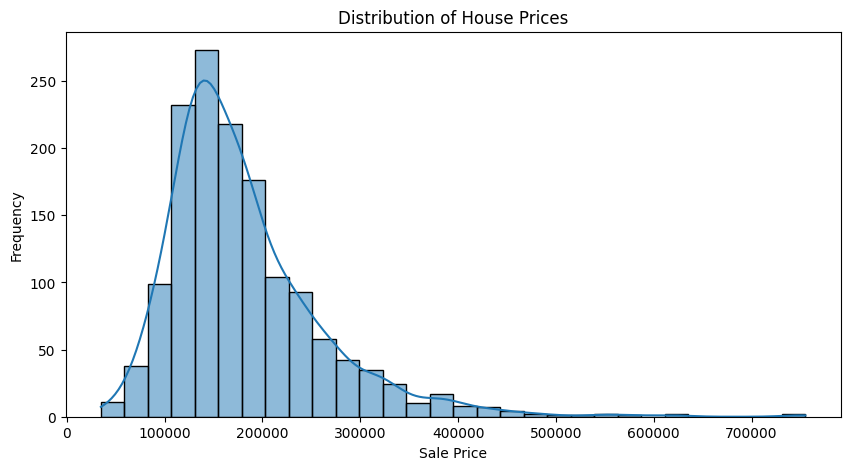

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(df['SalePrice'], bins=30, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

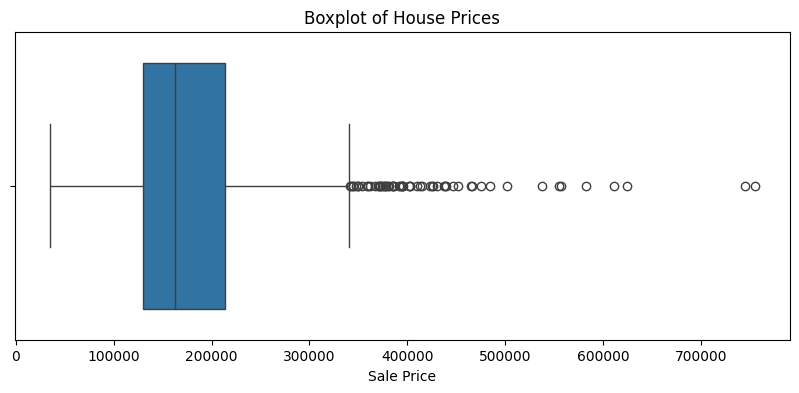

In [8]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['SalePrice'])

plt.title('Boxplot of House Prices')
plt.xlabel('Sale Price')

plt.show()

In [9]:
print("Minimum House Price:", df['SalePrice'].min())
print("Maximum House Price:", df['SalePrice'].max())
print("Average House Price:", df['SalePrice'].mean())
print("Median House Price:", df['SalePrice'].median())

Minimum House Price: 34900
Maximum House Price: 755000
Average House Price: 180921.19589041095
Median House Price: 163000.0


### 7. Feature Selection

Feature selection is the process of identifying the important variables that influence house prices.

In this project, the following features are selected:

1. **OverallQual** – Overall quality of the house.
2. **GrLivArea** – Above-ground living area.
3. **TotalBsmtSF** – Total basement area.
4. **GarageCars** – Garage capacity in number of cars.
5. **FullBath** – Number of full bathrooms.
6. **YearBuilt** – Year in which the house was constructed.
7. **LotArea** – Total land area.

These features are selected because they represent the size, quality, facilities, and age of a house, which may influence its selling price.

In [10]:
selected_features = [
    'OverallQual',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageCars',
    'FullBath',
    'YearBuilt',
    'LotArea',
    'SalePrice'
]

correlation = df[selected_features].corr()

print("Correlation with SalePrice:")
print(correlation['SalePrice'].sort_values(ascending=False))

Correlation with SalePrice:
SalePrice      1.000000
OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
TotalBsmtSF    0.613581
FullBath       0.560664
YearBuilt      0.522897
LotArea        0.263843
Name: SalePrice, dtype: float64


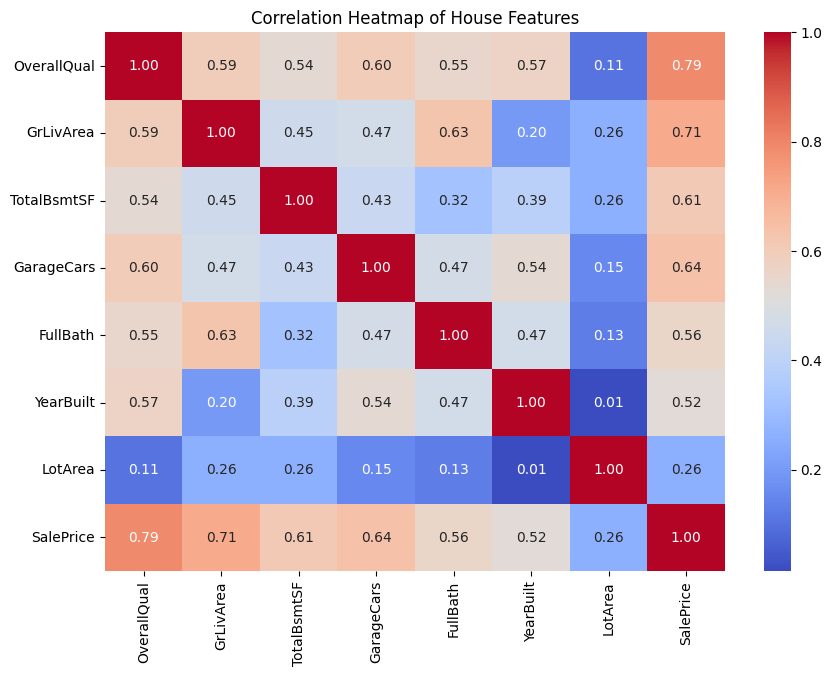

In [11]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of House Features')
plt.show()

### 8. Correlation Analysis – Interpretation

The correlation analysis helps identify the relationship between housing features and SalePrice.

Features with higher positive correlation may have a stronger positive relationship with house prices. OverallQual and GrLivArea are expected to show strong positive relationships with SalePrice.

Correlation indicates association and does not necessarily prove causation.

### 9. Data Preprocessing

Data preprocessing is the process of preparing raw data for machine learning. It includes handling missing values, converting categorical data into numerical format, and preparing features for model training.

#### 9.1 Handling Missing Values

Missing values are empty or unavailable data entries. They are handled using suitable imputation techniques.

Numerical missing values are replaced with the median, while categorical missing values are replaced with the most frequent value.

In [12]:
X = df.drop(['SalePrice', 'Id'], axis=1)
y = df['SalePrice']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1460, 79)
Target Shape: (1460,)


In [13]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 36
Categorical Features: 43


#### 9.2 Missing Value Imputation and One-Hot Encoding

Numerical features are processed using median imputation. Categorical features are processed using the most frequent value.

One-Hot Encoding converts categorical values into numerical binary columns so that machine learning algorithms can process them.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numerical_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


### 10. Splitting the Dataset

The dataset is divided into two parts:

- Training Data – 80% of the dataset is used to train the machine learning model.
- Testing Data – 20% of the dataset is used to evaluate the model.

This helps measure how well the model performs on unseen data.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

NameError: name 'train_test_split' is not defined

In [18]:
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)
print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Data Shape: (1168, 79)
Testing Data Shape: (292, 79)
Training Target Shape: (1168,)
Testing Target Shape: (292,)


In [20]:
from sklearn.linear_model import LinearRegression

In [21]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [22]:
y_pred = model.predict(X_test)

print("Actual House Prices:")
print(y_test.head().values)

print("\nPredicted House Prices:")
print(y_pred[:5])

Actual House Prices:
[154500 325000 115000 159000 315500]

Predicted House Prices:
[151971.20051183 356441.14089892  95590.88330007 177919.63763369
 342171.21147719]


In [23]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [24]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error (MSE):", round(mse, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("Mean Absolute Error (MAE):", round(mae, 2))
print("R-squared Score:", round(r2, 4))

Mean Squared Error (MSE): 979376460.09
Root Mean Squared Error (RMSE): 31294.99
Mean Absolute Error (MAE): 20466.13
R-squared Score: 0.8723


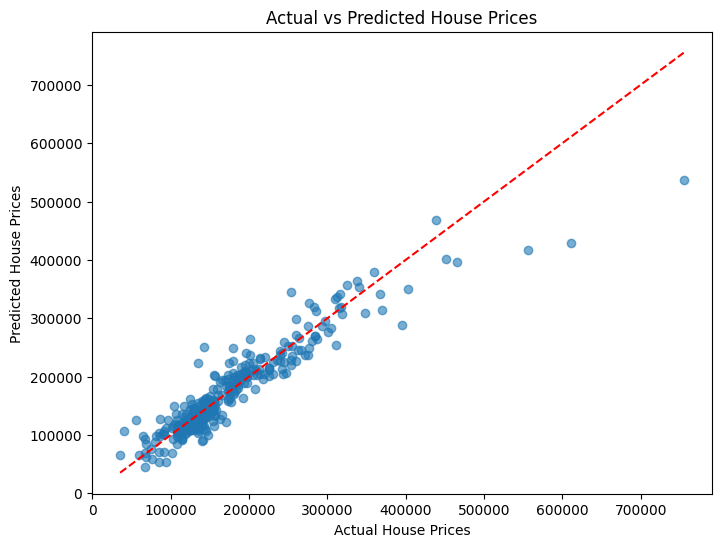

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--'
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()

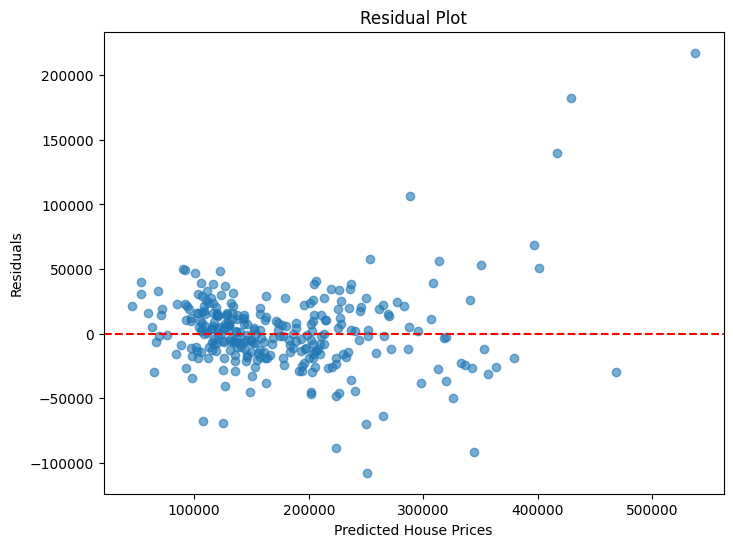

In [26]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

Residual Analysis:

Residual analysis is used to understand the errors made by the Linear Regression model. The residual plot shows the difference between actual and predicted house prices. A random distribution of points around the zero line indicates that the model fits the data reasonably well.

In [27]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()

coefficients = model.named_steps['regressor'].coef_

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['AbsoluteCoefficient'] = coef_df['Coefficient'].abs()

coef_df = coef_df.sort_values(
    by='AbsoluteCoefficient',
    ascending=False
)

display(coef_df.head(15))

,Feature,Coefficient,AbsoluteCoefficient
78,cat__Neighborhood_NoRidge,41901.268218,41901.268218
85,cat__Neighborhood_StoneBr,39134.933544,39134.933544
124,cat__RoofMatl_ClyTile,-29057.711990,29057.711990
259,cat__PoolQC_Ex,28020.792433,28020.792433
261,cat__PoolQC_Gd,-24972.333443,24972.333443
79,cat__Neighborhood_NridgHt,24777.963772,24777.963772
101,cat__Condition2_PosN,-24387.894785,24387.894785
134,cat__Exterior1st_BrkFace,23198.043843,23198.043843
153,cat__Exterior2nd_ImStucc,21429.506595,21429.506595
74,cat__Neighborhood_Mitchel,-21248.184226,21248.184226


Feature Coefficient Analysis:

Feature coefficient analysis helps identify how different house features influence the predicted house price. Positive coefficients indicate a positive relationship, while negative coefficients indicate a negative relationship. This analysis helps understand the Linear Regression model.

In [28]:
from sklearn.linear_model import Ridge, Lasso

In [29]:
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Ridge(alpha=10.0))
])

lasso_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', Lasso(alpha=100.0, max_iter=10000))
])

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

print("Ridge and Lasso Models Trained Successfully!")

Ridge and Lasso Models Trained Successfully!


In [30]:
models = {
    'Linear Regression': model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model
}

results = []

for name, mdl in models.items():
    predictions = mdl.predict(X_test)

    mse = mean_squared_error(y_test, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': name,
        'MSE': round(mse, 2),
        'RMSE': round(rmse, 2),
        'R2 Score': round(r2, 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,MSE,RMSE,R2 Score
0,Linear Regression,9.793765e+08,31294.99,0.8723
1,Ridge Regression,1.194765e+09,34565.37,0.8442
2,Lasso Regression,8.011280e+08,28304.21,0.8956


# Conclusion

The House Price Prediction project was successfully developed using Linear Regression.

The project used the House Prices dataset to analyse different factors affecting house prices. Data preprocessing techniques such as handling missing values and encoding categorical variables were applied.

The Linear Regression model was trained using 80% of the dataset and tested using the remaining 20%.

The model performance was evaluated using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R-squared score.

Actual vs Predicted and Residual plots were created to understand the prediction performance. Ridge and Lasso Regression models were also compared with Linear Regression.

This project helped demonstrate how machine learning techniques can be used to predict house prices based on different property features.